# HOUSE PRICE PREDICTION 

In [46]:
import sys
from pathlib import Path

## Import libraries 

In [47]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 


## Load dataset

In [48]:
df = pd.read_csv("/Applications/Coding/Project's/House Price Prediction /data/house_prices_practice.csv")

## Understand the dataset

In [49]:
df.head()

,Id,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,BedroomAbvGr,LotArea,SalePrice
0,1,7,1560,0,1658,1969,2,1,8059,177106
1,2,4,2827,2,1319,2012,3,4,13530,301044
2,3,8,3920,0,841,2010,1,4,9010,360609
3,4,5,3044,0,1058,1998,0,4,13207,240556
4,5,7,801,1,2428,2020,0,1,9117,193656


In [50]:
df.tail()

,Id,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,BedroomAbvGr,LotArea,SalePrice
295,296,1,3495,1,1792,1954,2,5,4978,250604
296,297,5,3438,3,1266,2003,0,1,9373,329906
297,298,6,1992,0,1148,1996,1,1,7907,184623
298,299,3,3722,1,1407,1998,1,1,8097,303345
299,300,9,1667,0,988,1958,2,1,14553,204982


In [51]:
df.shape

(300, 10)

In [52]:
df.describe()

,Id,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,BedroomAbvGr,LotArea,SalePrice
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,5.326667,2307.386667,1.330000,1468.796667,1986.163333,1.523333,2.926667,8969.453333,252262.903333
std,86.746758,2.873001,1042.561303,1.109898,672.333705,21.377089,1.131543,1.456604,3753.531132,74998.055214
min,1.000000,1.000000,504.000000,0.000000,303.000000,1950.000000,0.000000,1.000000,2009.000000,82494.000000
25%,75.750000,3.000000,1392.250000,0.000000,903.000000,1967.000000,0.000000,2.000000,5996.250000,190355.250000
50%,150.500000,5.000000,2265.500000,1.000000,1502.000000,1986.000000,2.000000,3.000000,9031.000000,251292.500000
75%,225.250000,8.000000,3306.500000,2.000000,2129.500000,2004.250000,3.000000,4.000000,12316.000000,307105.000000
max,300.000000,10.000000,3998.000000,3.000000,2492.000000,2023.000000,3.000000,5.000000,14987.000000,435291.000000


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Id            300 non-null    int64
 1   OverallQual   300 non-null    int64
 2   GrLivArea     300 non-null    int64
 3   GarageCars    300 non-null    int64
 4   TotalBsmtSF   300 non-null    int64
 5   YearBuilt     300 non-null    int64
 6   FullBath      300 non-null    int64
 7   BedroomAbvGr  300 non-null    int64
 8   LotArea       300 non-null    int64
 9   SalePrice     300 non-null    int64
dtypes: int64(10)
memory usage: 23.6 KB


In [54]:
df.dtypes

Id              int64
OverallQual     int64
GrLivArea       int64
GarageCars      int64
TotalBsmtSF     int64
YearBuilt       int64
FullBath        int64
BedroomAbvGr    int64
LotArea         int64
SalePrice       int64
dtype: object

In [55]:
df.isnull().sum()

Id              0
OverallQual     0
GrLivArea       0
GarageCars      0
TotalBsmtSF     0
YearBuilt       0
FullBath        0
BedroomAbvGr    0
LotArea         0
SalePrice       0
dtype: int64

In [56]:
df.duplicated().sum()

np.int64(0)

In [57]:
df.columns

Index(['Id', 'OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF',
       'YearBuilt', 'FullBath', 'BedroomAbvGr', 'LotArea', 'SalePrice'],
      dtype='str')

## Exploratory Data Analysis (EDA)

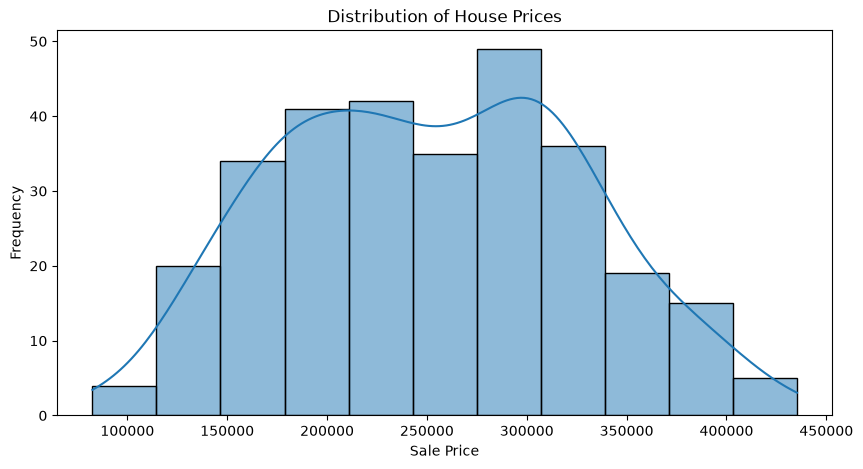

In [58]:
plt.figure(figsize=(10, 5))

sns.histplot(df['SalePrice'], kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')

plt.show()

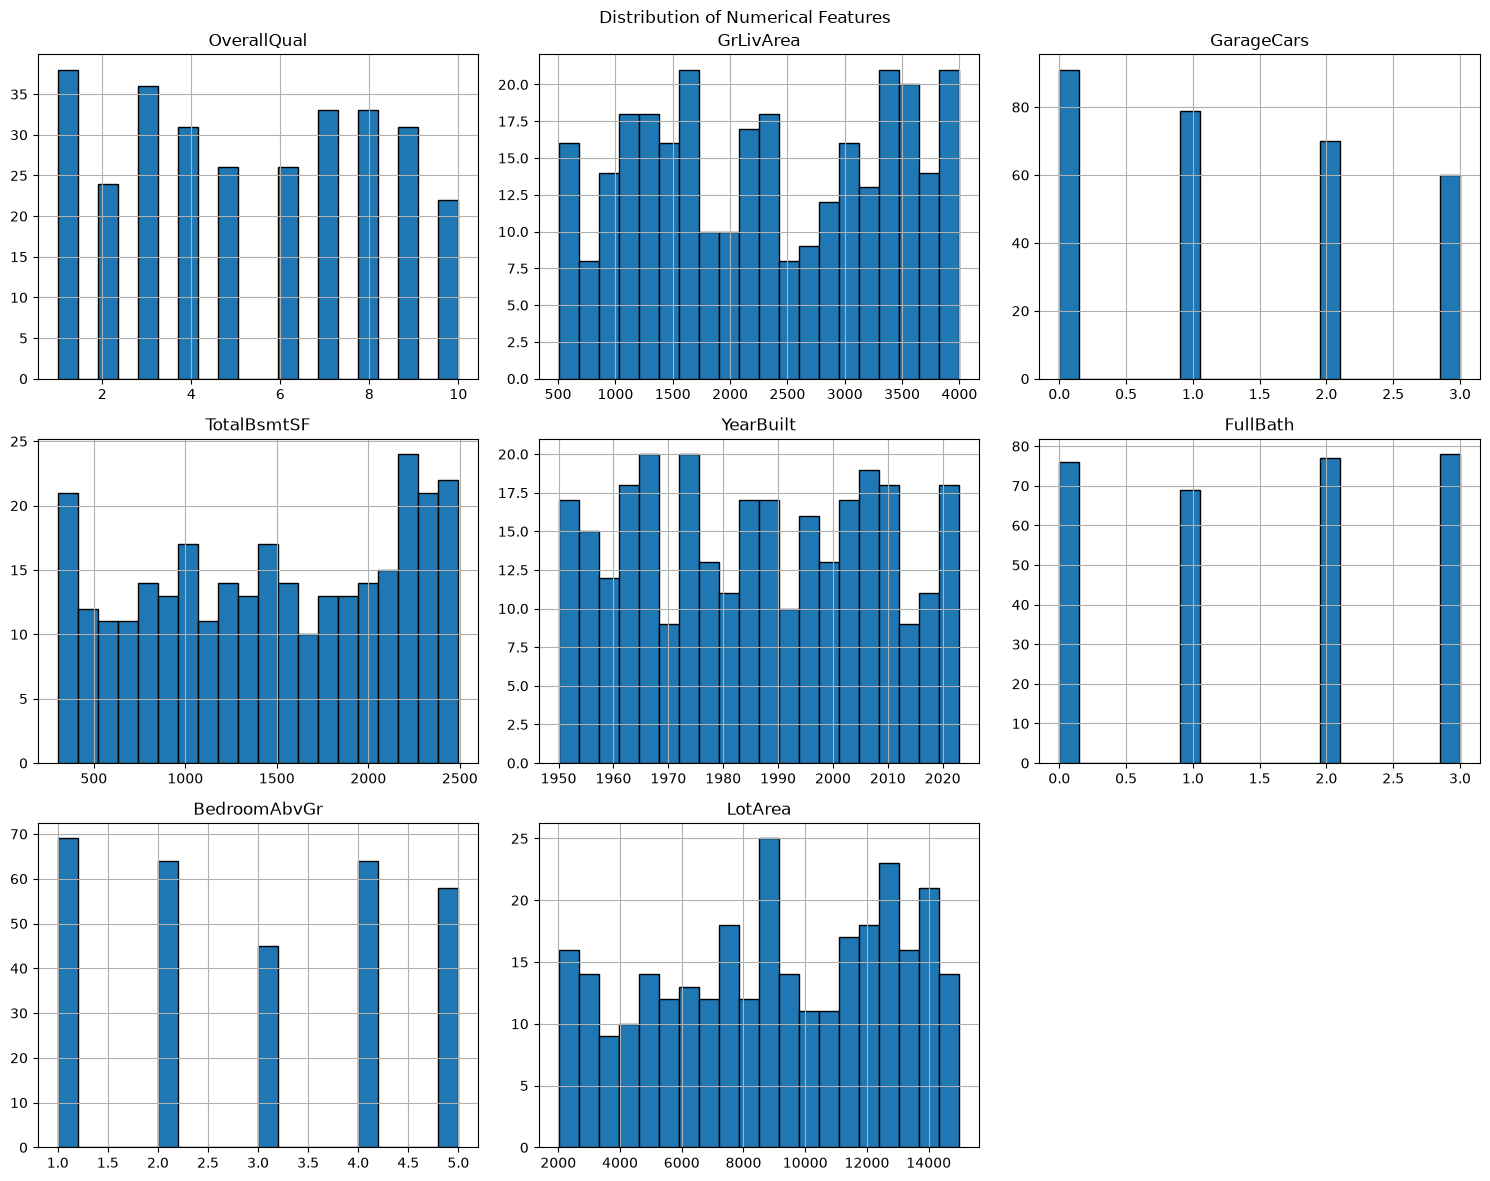

In [59]:
features = [
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'TotalBsmtSF',
    'YearBuilt',
    'FullBath',
    'BedroomAbvGr',
    'LotArea'
]

df[features].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features')

plt.tight_layout()
plt.show()

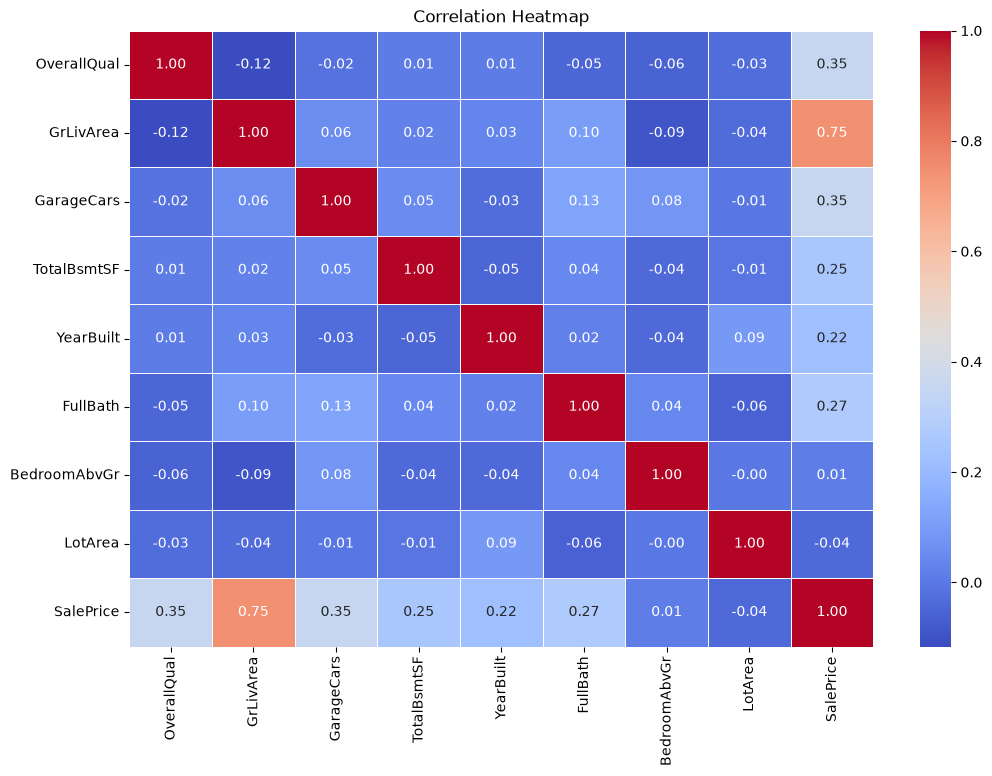

In [60]:
plt.figure(figsize=(12, 8))

correlation = df.drop(columns=['Id']).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.show()

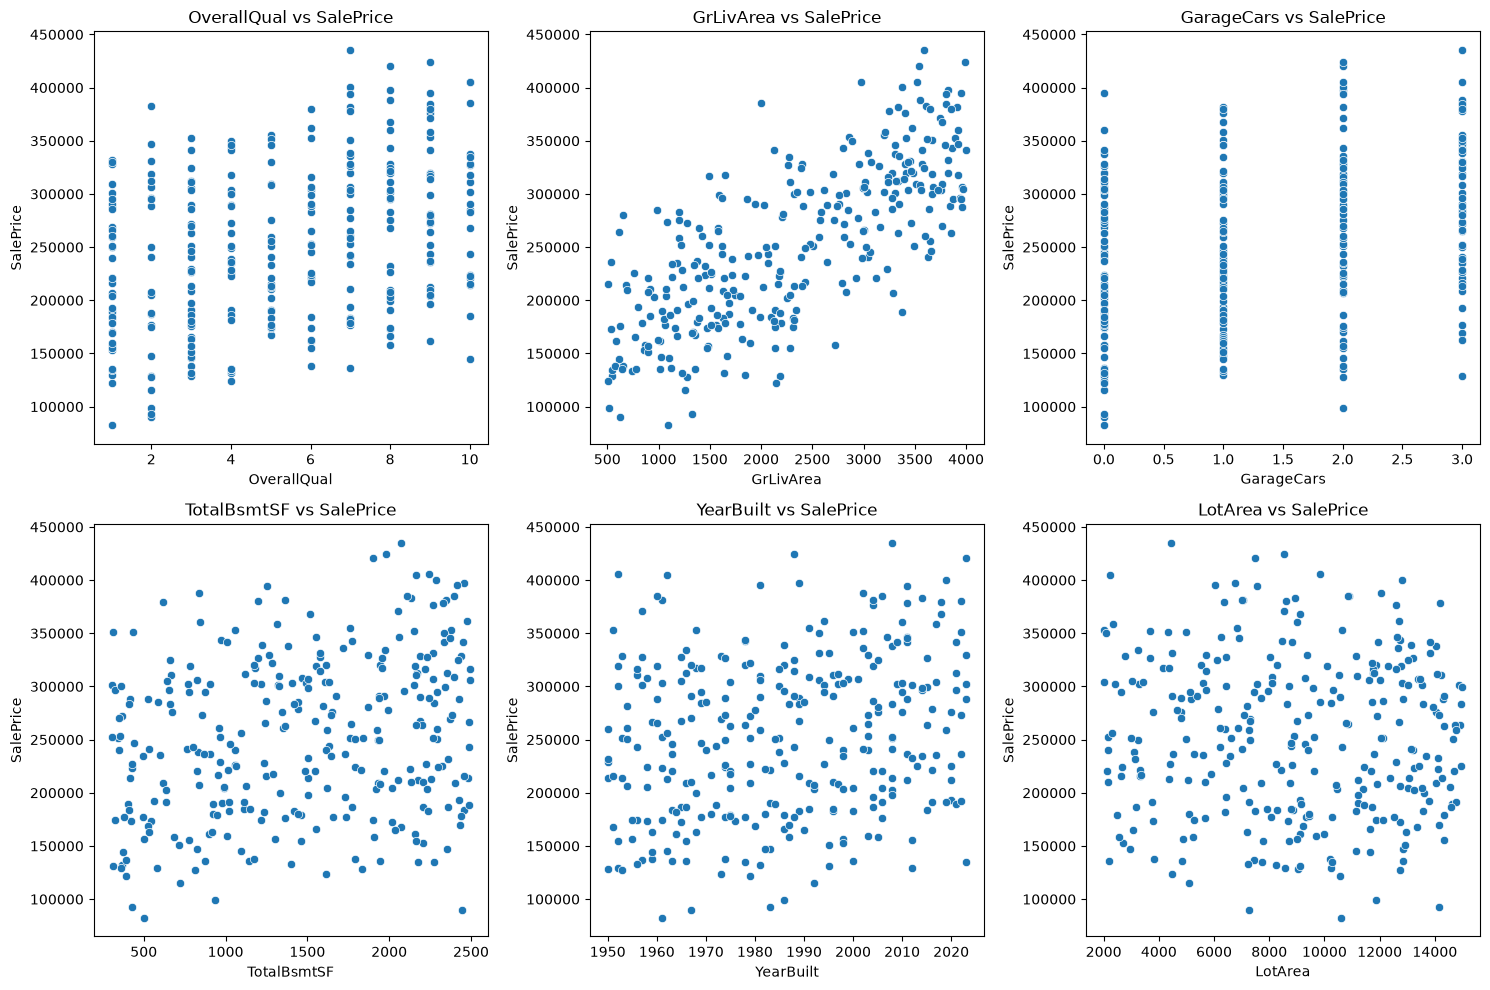

In [61]:
plt.figure(figsize=(15, 10))

features = [
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'TotalBsmtSF',
    'YearBuilt',
    'LotArea'
]

for i, feature in enumerate(features, 1):

    plt.subplot(2, 3, i)

    sns.scatterplot(
        data=df,
        x=feature,
        y='SalePrice'
    )

    plt.title(f'{feature} vs SalePrice')

plt.tight_layout()
plt.show()

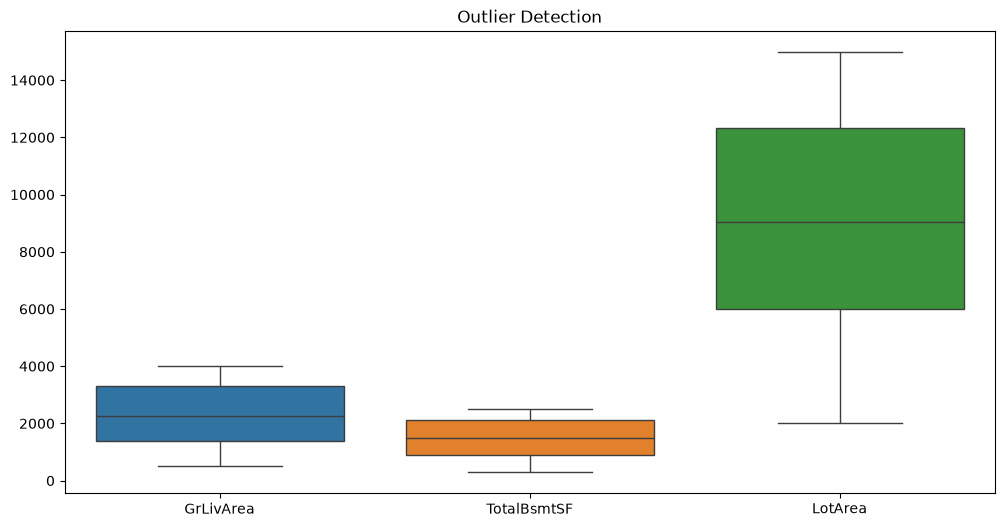

In [62]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[
        ['GrLivArea', 'TotalBsmtSF', 'LotArea']
    ]
)

plt.title('Outlier Detection')

plt.show()

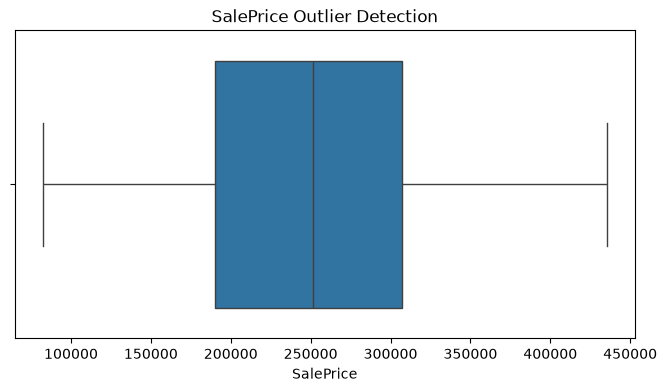

In [63]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['SalePrice'])

plt.title('SalePrice Outlier Detection')

plt.show()

In [64]:
target_corr = (
    df.drop(columns=['Id'])
      .corr()['SalePrice']
      .sort_values(ascending=False)
)

print(target_corr)

SalePrice       1.000000
GrLivArea       0.745095
OverallQual     0.352899
GarageCars      0.351321
FullBath        0.273731
TotalBsmtSF     0.250178
YearBuilt       0.222142
BedroomAbvGr    0.014113
LotArea        -0.038982
Name: SalePrice, dtype: float64


## Data Preprocessing

In [65]:
df = df.drop(columns=['Id'])

print(df.head())
print("Dataset Shape:", df.shape)

   OverallQual  GrLivArea  GarageCars  TotalBsmtSF  YearBuilt  FullBath  \
0            7       1560           0         1658       1969         2   
1            4       2827           2         1319       2012         3   
2            8       3920           0          841       2010         1   
3            5       3044           0         1058       1998         0   
4            7        801           1         2428       2020         0   

   BedroomAbvGr  LotArea  SalePrice  
0             1     8059     177106  
1             4    13530     301044  
2             4     9010     360609  
3             4    13207     240556  
4             1     9117     193656  
Dataset Shape: (300, 9)


In [67]:
X = df.drop(columns=['SalePrice'])

y = df['SalePrice']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (300, 8)
Target Shape: (300,)


In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (240, 8)
X_test: (60, 8)
y_train: (240,)
y_test: (60,)


## Model Training – Linear Regression

In [69]:
from sklearn.linear_model import LinearRegression

# Create model
lr_model = LinearRegression()

In [70]:
# Train model
lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [71]:
# Predict house prices
y_pred_lr = lr_model.predict(X_test)

print("Predicted Prices:")
print(y_pred_lr[:10])

Predicted Prices:
[239161.36318915 190489.66798467 398000.95746315 223169.46755224
 135188.39570785 180259.03980676 283708.27101143 204535.26547718
 205837.9417306  171505.33195999]


In [72]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred_lr)

mse = mean_squared_error(y_test, y_pred_lr)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Evaluation")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Evaluation
MAE: 10431.655979708583
MSE: 156386511.4191235
RMSE: 12505.459264622132
R2 Score: 0.9724369952260682


In [73]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_lr
})

print(comparison.head(10))

   Actual Price  Predicted Price
0        224163    239161.363189
1        203881    190489.667985
2        380236    398000.957463
3        211664    223169.467552
4        122139    135188.395708
5        180067    180259.039807
6        275810    283708.271011
7        209025    204535.265477
8        213952    205837.941731
9        154885    171505.331960


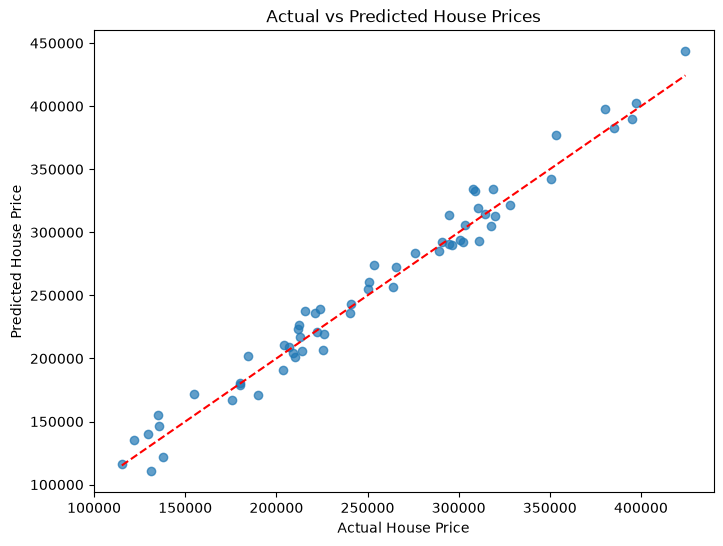

In [74]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_lr,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')

plt.title('Actual vs Predicted House Prices')

plt.show()